# 03_03 Gaussian Mixtures and the EM Algorithm

**Learning objectives**
- Model data from several hidden groups with a **mixture** distribution, and understand the two-step **generative story**.
- Derive the mixture's mean and variance, and the **responsibilities** (posterior probability of each group).
- Fit a **Gaussian mixture** with the **EM algorithm**, written out step by step, and choose the number of components with **BIC**.
- Apply it to real data (Old Faithful geyser eruptions), then to customer segments.

**Prerequisites:** [03_01 Multivariate Normal](03_01_multivariate_normal.ipynb), [00_05 Bayes' theorem](../../module_00_foundations/notebooks/00_05_bayes_theorem.ipynb), [00_02 Expectation and variance](../../module_00_foundations/notebooks/00_02_expectation_moments.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers. The geyser data are read later from `../data/` (run `../data/download_data.py` if missing).

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Normal density** $\mathcal N(x\mid\mu,\sigma^2)$, and the multivariate version with covariance $\Sigma$ (03_01).
- **Bayes' theorem:** $P(k\mid x)=\dfrac{P(x\mid k)P(k)}{\sum_jP(x\mid j)P(j)}$.
- **Law of total expectation:** $E[X]=\sum_kP(k)E[X\mid k]$, and **total variance** $\mathrm{Var}(X)=E[\mathrm{Var}(X\mid K)]+\mathrm{Var}(E[X\mid K])$.
- **Log-likelihood:** $\ell=\sum_i\ln f(x_i)$; maximum likelihood picks parameters that maximize it.

## 3. Intuition and story

A histogram with **two humps** usually means the data come from **two groups mixed together**: short and long geyser eruptions, casual and heavy-spending customers, healthy and sick patients. No single Normal fits a two-humped histogram. A **mixture model** says: first pick a group with probabilities $\pi_1,\pi_2,\dots$ (the mixing weights), then draw the observation from that group's Normal distribution.

We usually do not see the group label. The **EM algorithm** estimates the groups and their Normals together by alternating two steps: (E) guess how likely each point belongs to each group (soft assignments), (M) re-estimate each group's parameters using those guesses as weights. Repeat until nothing changes.

## 4. Formal definition

$$f(x)=\sum_{k=1}^K\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k),\qquad\pi_k\ge0,\ \sum_k\pi_k=1.$$
Generative story: draw a label $Z\sim\text{Categorical}(\pi)$, then $X\mid Z=k\sim\mathcal N(\mu_k,\Sigma_k)$. The **responsibility** of component $k$ for a point $x$ is
$$r_k(x)=P(Z=k\mid x)=\frac{\pi_k\mathcal N(x\mid\mu_k,\Sigma_k)}{\sum_j\pi_j\mathcal N(x\mid\mu_j,\Sigma_j)}.$$

**EM updates** (with $n$ points and $r_{ik}=r_k(x_i)$, $N_k=\sum_ir_{ik}$):
$$\pi_k=\frac{N_k}n,\qquad\mu_k=\frac1{N_k}\sum_ir_{ik}x_i,\qquad\Sigma_k=\frac1{N_k}\sum_ir_{ik}(x_i-\mu_k)(x_i-\mu_k)^\top.$$

## 5. Derivations

**Mixture mean.** $E[X]=\sum_k\pi_k\mu_k$ (law of total expectation).

**Mixture variance (1D).** By the law of total variance,
$$\mathrm{Var}(X)=\underbrace{\sum_k\pi_k\sigma_k^2}_{\text{within groups}}+\underbrace{\sum_k\pi_k(\mu_k-\bar\mu)^2}_{\text{between groups}},\qquad\bar\mu=\sum_k\pi_k\mu_k.$$
A mixture is more spread than the average of its parts when the means differ.

**Responsibilities from Bayes.** $P(Z=k\mid x)\propto P(x\mid Z=k)P(Z=k)=\pi_k\mathcal N(x\mid\mu_k,\Sigma_k)$, normalized over $k$.

**Why EM works.** The log-likelihood $\sum_i\ln\sum_k\pi_k\mathcal N(x_i\mid\mu_k,\Sigma_k)$ has a log of a sum, which is hard to maximize directly. If the labels $z_i$ were known, the log-likelihood would split by group and each group's MLE is a weighted mean and covariance. EM replaces the unknown labels by their expected values $r_{ik}$ (E step) and then maximizes the expected complete-data log-likelihood (M step). Each iteration **never decreases** the likelihood (a standard result via Jensen's inequality), so it converges to a local maximum.

**Model selection.** More components always increase the likelihood; the **BIC** $=p\ln n-2\ell$ ($p$ = number of free parameters, lower is better) balances fit and complexity. In 1D a $K$-component mixture has $3K-1$ parameters; in 2D with full covariances, $6K-1$.

**In plain words.** EM is "k-means with soft assignments and with shapes": guess memberships, update the groups, repeat.

### In plain words: the derivations in everyday language


- **A Gaussian mixture is "pick a group, then draw from that group's Normal":** with probability $\pi_k$ the observation comes from component $k$, a Normal$(\mu_k,\sigma_k^2)$. The density is the weighted sum $\sum_k\pi_k\,\phi_k(x)$, which can have several humps, skewness or heavy tails even though every part is a simple bell.
- **The mean is the weighted mean, but the variance has two pieces:** the average within-component variance plus the spread of the component means around the overall mean (the law of total variance of 00_03). Two well-separated groups give a large total variance even if each group is tight.
- **The "responsibility" is Bayes' theorem:** given an observation $x$, the probability that it came from component $k$ is $\pi_k\phi_k(x)/\sum_j\pi_j\phi_j(x)$. This is the soft group membership used for clustering.
- **EM fits a mixture by alternating two steps:** the **E-step** computes the responsibilities with the current parameters; the **M-step** re-estimates each component's weight, mean and variance as responsibility-weighted averages. Each round can only increase the likelihood, so it climbs to a (local) peak.
- **The likelihood is not unique and can misbehave:** results depend on the starting values, a component may collapse onto one point (variance to 0), and the number of components must be chosen (for instance with BIC).

## 6. Properties and relationships

- **Flexible:** with enough components a Gaussian mixture approximates any smooth density.
- **Soft clustering:** responsibilities give *probabilities* of membership; hard labels take the largest one.
- **K-means** is the limit of a Gaussian mixture with equal spherical covariances and hard assignments.
- **Label switching and local maxima:** components can be permuted freely and EM depends on the start; use several random starts and keep the best likelihood.
- **Degenerate solutions:** a component collapsing onto one point has infinite likelihood; guard with a minimum variance.
- **Dirichlet prior on the weights** (03_02) gives a Bayesian mixture.

## 7. 2D visuals

### 7.1 One Normal cannot fit a two-humped histogram
We simulate a 1D mixture of 40 % N(2, 0.6) and 60 % N(5, 1). The mixture density is the weighted sum of the two bells.

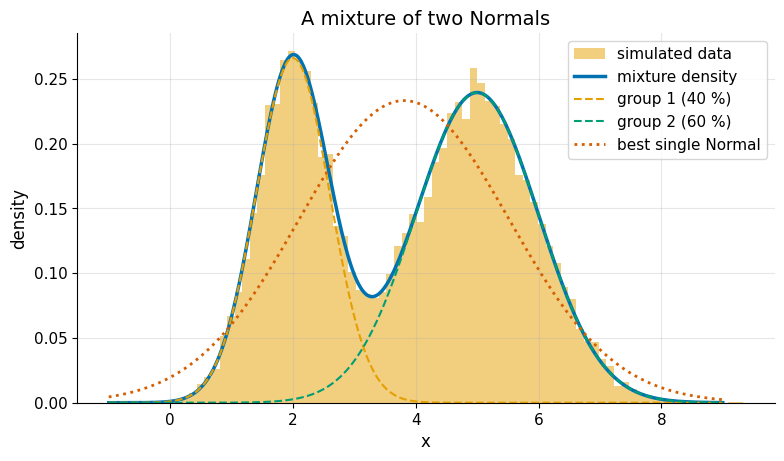

In [2]:
weights = np.array([0.4, 0.6])
means = np.array([2.0, 5.0])
sds = np.array([0.6, 1.0])
x_axis = np.linspace(-1, 9, 600)
components = [w * stats.norm(m, s).pdf(x_axis) for w, m, s in zip(weights, means, sds)]
mixture_density = sum(components)

labels = rng.choice(2, size=20_000, p=weights)                       # step 1: pick a group
samples = rng.normal(means[labels], sds[labels])                     # step 2: draw from that group's Normal
mu_single, sd_single = stats.norm.fit(samples)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(samples, bins=80, density=True, color=SIM, alpha=0.5, label="simulated data")
ax.plot(x_axis, mixture_density, color=MAIN, linewidth=2.5, label="mixture density")
for component, color, name in zip(components, COLORS[1:], ["group 1 (40 %)", "group 2 (60 %)"]):
    ax.plot(x_axis, component, "--", color=color, label=name)
ax.plot(x_axis, stats.norm(mu_single, sd_single).pdf(x_axis), ":", color=HIGHLIGHT, linewidth=2, label="best single Normal")
ax.set_title("A mixture of two Normals")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.2 Responsibilities
For each x, the probability that it came from group 2; the curve switches from 0 to 1 around the point where the weighted bells cross.

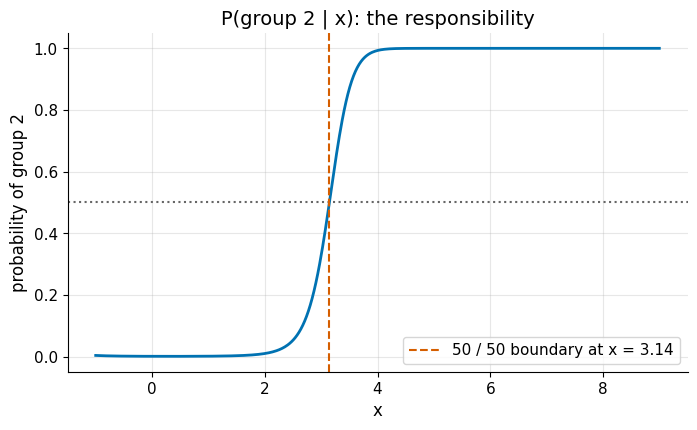

In [3]:
responsibility_group2 = components[1] / mixture_density
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(x_axis, responsibility_group2, color=MAIN, linewidth=2)
ax.axhline(0.5, color=NEUTRAL, linestyle=":")
boundary = x_axis[np.argmin(np.abs(responsibility_group2 - 0.5))]
ax.axvline(boundary, color=HIGHLIGHT, linestyle="--", label=f"50 / 50 boundary at x = {boundary:.2f}")
ax.set_title("P(group 2 | x): the responsibility")
ax.set_xlabel("x")
ax.set_ylabel("probability of group 2")
ax.legend()
plt.show()

### 7.3 The EM algorithm in action (1D)
Starting from a poor guess, the fitted mixture moves toward the data and the log-likelihood rises at every iteration.

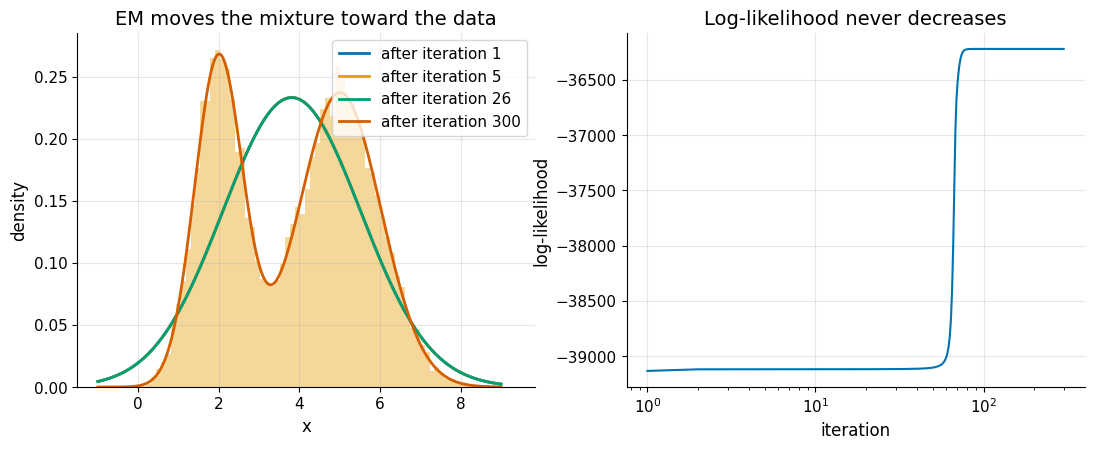

final estimates: weights [0.397 0.603] means [1.998 5.005] SDs [0.598 1.014] (truth 0.4/0.6, 2/5, 0.6/1)


In [4]:
def em_1d(data, k, n_iterations, seed_means):
    """Fit a 1D Gaussian mixture with EM. Returns the parameters after every iteration and the log-likelihoods."""
    pi = np.full(k, 1 / k)
    mu = np.array(seed_means, dtype=float)
    sd = np.full(k, data.std())
    history, log_likelihoods = [], []
    for _ in range(n_iterations):
        density = np.array([pi[j] * stats.norm(mu[j], sd[j]).pdf(data) for j in range(k)])        # shape (k, n)
        log_likelihoods.append(np.log(density.sum(axis=0)).sum())
        responsibilities = density / density.sum(axis=0)                                            # E step
        n_k = responsibilities.sum(axis=1)                                                          # M step
        pi = n_k / len(data)
        mu = (responsibilities * data).sum(axis=1) / n_k
        sd = np.sqrt((responsibilities * (data - mu[:, None]) ** 2).sum(axis=1) / n_k)
        history.append((pi.copy(), mu.copy(), sd.copy()))
    return history, log_likelihoods

history, log_likelihoods = em_1d(samples, 2, 300, seed_means=[3.5, 4.0])
fig, (ax_fit, ax_ll) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_fit.hist(samples, bins=80, density=True, color=SIM, alpha=0.4)
for iteration, color in zip([0, 4, 25, 299], COLORS):
    pi, mu, sd = history[iteration]
    ax_fit.plot(x_axis, sum(pi[j] * stats.norm(mu[j], sd[j]).pdf(x_axis) for j in range(2)), color=color, linewidth=2, label=f"after iteration {iteration + 1}")
ax_fit.set_title("EM moves the mixture toward the data")
ax_fit.set_xlabel("x")
ax_fit.set_ylabel("density")
ax_fit.legend()
ax_ll.plot(range(1, 301), log_likelihoods, color=MAIN)
ax_ll.set_xscale("log")
ax_ll.set_title("Log-likelihood never decreases")
ax_ll.set_xlabel("iteration")
ax_ll.set_ylabel("log-likelihood")
plt.show()
assert all(b >= a - 1e-9 for a, b in zip(log_likelihoods, log_likelihoods[1:]))
print("final estimates: weights", history[-1][0].round(3), "means", history[-1][1].round(3), "SDs", history[-1][2].round(3), "(truth 0.4/0.6, 2/5, 0.6/1)")

## 8. 3D visuals

### 8.1 Static: a 2D Gaussian mixture density surface
Three groups give three hills; the surface is the weighted sum of their bivariate Normal densities.

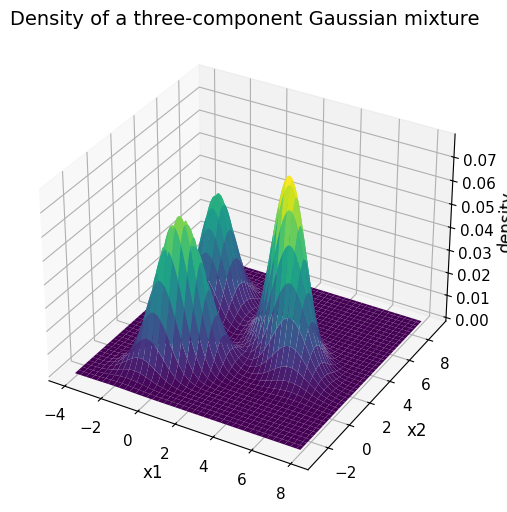

In [5]:
mix_weights = [0.3, 0.45, 0.25]
mix_means = [np.array([0.0, 0.0]), np.array([4.0, 3.0]), np.array([-1.0, 5.0])]
mix_covs = [np.array([[1.0, 0.5], [0.5, 0.8]]), np.array([[1.2, -0.6], [-0.6, 1.0]]), np.array([[0.6, 0.0], [0.0, 1.0]])]
grid = np.linspace(-4, 8, 120)
G1, G2 = np.meshgrid(grid, np.linspace(-3, 9, 120))
density = sum(w * stats.multivariate_normal(m, c).pdf(np.dstack([G1, G2])) for w, m, c in zip(mix_weights, mix_means, mix_covs))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(G1, G2, density, cmap="viridis", edgecolor="none")
ax.set_title("Density of a three-component Gaussian mixture")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("density")
ax.view_init(elev=32, azim=-60)
plt.show()

### 8.2 Static: mixture samples colored by their hidden group

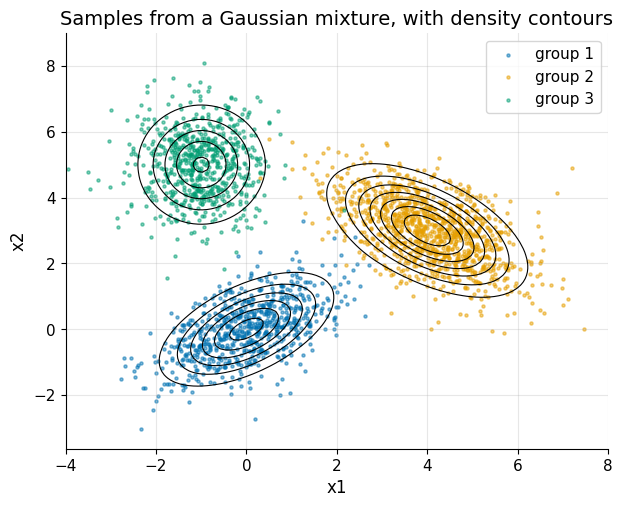

In [6]:
group = rng.choice(3, size=2500, p=mix_weights)
points = np.array([rng.multivariate_normal(mix_means[g], mix_covs[g]) for g in group])
fig, ax = plt.subplots(figsize=(7, 5.4))
for g, color in zip(range(3), COLORS):
    ax.scatter(points[group == g, 0], points[group == g, 1], s=5, alpha=0.5, color=color, label=f"group {g + 1}")
ax.contour(G1, G2, density, levels=8, colors="black", linewidths=0.8)
ax.set_title("Samples from a Gaussian mixture, with density contours")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
plt.show()

### 8.3 Interactive Plotly version of 8.1

In [7]:
fig = go.Figure(go.Surface(x=grid, y=np.linspace(-3, 9, 120), z=density, colorscale="Viridis"))
fig.update_layout(title="Three-component Gaussian mixture density", width=750, height=550, scene=dict(xaxis_title="x1", yaxis_title="x2", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Mixture mean and variance (law of total variance)

In [8]:
mixture_mean = (weights * means).sum()
within = (weights * sds**2).sum()
between = (weights * (means - mixture_mean) ** 2).sum()
print(f"mean: theory {mixture_mean:.3f}, simulated {samples.mean():.3f}")
print(f"variance: within {within:.3f} + between {between:.3f} = {within + between:.3f}, simulated {samples.var():.3f}")
assert np.isclose(samples.var(), within + between, rtol=0.03)

mean: theory 3.800, simulated 3.810
variance: within 0.744 + between 2.160 = 2.904, simulated 2.928


### 9.2 EM recovers the parameters from different starts
We fit 200 simulated datasets of 500 points each; the average estimates are close to the truth.

In [9]:
estimates = []
for _ in range(200):
    z = rng.choice(2, size=500, p=weights)
    data = rng.normal(means[z], sds[z])
    pi_hat, mu_hat, sd_hat = em_1d(data, 2, 60, seed_means=[data.min() + 1, data.max() - 1])[0][-1]
    order = np.argsort(mu_hat)                                           # fix label switching: sort by mean
    estimates.append(np.concatenate([pi_hat[order], mu_hat[order], sd_hat[order]]))
estimates = np.array(estimates)
print("average estimates (w1 w2 mu1 mu2 sd1 sd2):", estimates.mean(axis=0).round(3), " truth:", np.concatenate([weights, means, sds]))

average estimates (w1 w2 mu1 mu2 sd1 sd2): [0.399 0.601 2.001 4.997 0.601 0.994]  truth: [0.4 0.6 2.  5.  0.6 1. ]


## 10. `scipy.stats` cheat sheet

`scipy` has no mixture class, but a mixture is easy to build from `stats` components: density = weighted sum of `pdf`s; sampling = choose a label, then sample that component; `stats.rv_continuous` can wrap it.

In [10]:
class Mixture1D:
    """A mixture of 1D Normals built from scipy.stats components."""
    def __init__(self, weights, means, sds):
        self.weights, self.components = np.array(weights), [stats.norm(m, s) for m, s in zip(means, sds)]
    def pdf(self, x):
        return sum(w * c.pdf(x) for w, c in zip(self.weights, self.components))
    def cdf(self, x):
        return sum(w * c.cdf(x) for w, c in zip(self.weights, self.components))
    def rvs(self, size, rng):
        picks = rng.choice(len(self.weights), size=size, p=self.weights)
        return np.array([self.components[k].rvs(random_state=rng) for k in picks])

model = Mixture1D([0.4, 0.6], [2, 5], [0.6, 1.0])
print("pdf(3.5)     :", round(model.pdf(3.5), 4))
print("cdf(3.5)     P(X <= 3.5):", round(model.cdf(3.5), 4))
print("sf(6)        :", round(1 - model.cdf(6), 4))
print("rvs(3)       :", model.rvs(3, np.random.default_rng(1)).round(2))
print("multivariate_normal for the 2D components: pdf at the first mean =", round(stats.multivariate_normal(mix_means[0], mix_covs[0]).pdf(mix_means[0]), 4))

pdf(3.5)     : 0.0894
cdf(3.5)     P(X <= 3.5): 0.4376
sf(6)        : 0.0952
rvs(3)       : [3.7  5.91 2.27]
multivariate_normal for the 2D components: pdf at the first mean = 0.2146


## 11. Real-world worked example: Old Faithful eruptions (real data)

**Data (real).** 272 eruptions of the Old Faithful geyser (Yellowstone National Park): the **duration** of the eruption (minutes) and the **waiting time** (minutes) until the next one (source and license in `../data/README.md`). The histogram of durations has two humps: short and long eruptions.

**Questions**
1. Fit a **2-component Gaussian mixture** to the durations with EM: weights, means, SDs.
2. A new eruption lasts **3.0 minutes**. What is the probability that it belongs to the "long" group?
3. Is 2 components right? Compare **BIC** for 1 to 4 components, then fit the 2D mixture of (duration, waiting).

272 eruptions; duration mean 3.49 (SD 1.14), waiting mean 70.9 (SD 13.6)


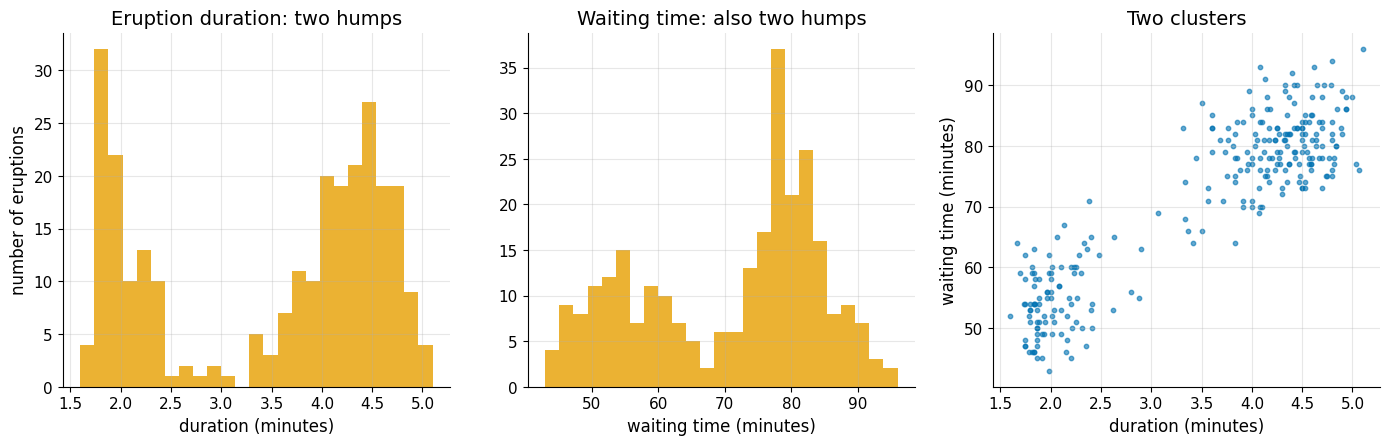

In [11]:
import pathlib
geyser_path = pathlib.Path("../data/geyser.csv")
if not geyser_path.exists():
    raise FileNotFoundError("Run `python ../data/download_data.py` first to download the dataset.")
geyser = pd.read_csv(geyser_path)
duration = geyser["duration"].to_numpy()
waiting = geyser["waiting"].to_numpy()
print(f"{len(geyser)} eruptions; duration mean {duration.mean():.2f} (SD {duration.std():.2f}), waiting mean {waiting.mean():.1f} (SD {waiting.std():.1f})")
fig, (ax_d, ax_w, ax_s) = plt.subplots(1, 3, figsize=(17, 4.6))
ax_d.hist(duration, bins=25, color=SIM, alpha=0.8)
ax_d.set_title("Eruption duration: two humps")
ax_d.set_xlabel("duration (minutes)")
ax_d.set_ylabel("number of eruptions")
ax_w.hist(waiting, bins=25, color=SIM, alpha=0.8)
ax_w.set_title("Waiting time: also two humps")
ax_w.set_xlabel("waiting time (minutes)")
ax_s.scatter(duration, waiting, s=10, alpha=0.6, color=MAIN)
ax_s.set_title("Two clusters")
ax_s.set_xlabel("duration (minutes)")
ax_s.set_ylabel("waiting time (minutes)")
plt.show()

### 11.1 By hand (the EM steps for one iteration, then the full fit)
**One EM iteration written out.** Start with $\pi=(0.5,0.5)$, $\mu=(2,4.5)$, $\sigma=(0.5,0.5)$. For each eruption $x_i$: (E) $r_{i2}=\dfrac{\pi_2\mathcal N(x_i\mid\mu_2,\sigma_2)}{\pi_1\mathcal N(x_i\mid\mu_1,\sigma_1)+\pi_2\mathcal N(x_i\mid\mu_2,\sigma_2)}$, $r_{i1}=1-r_{i2}$; (M) $N_k=\sum r_{ik}$, $\pi_k=N_k/n$, $\mu_k=\sum r_{ik}x_i/N_k$, $\sigma_k^2=\sum r_{ik}(x_i-\mu_k)^2/N_k$. We iterate this loop until the log-likelihood stops changing.

**Q2 (by hand with the fitted values).** $P(\text{long}\mid3.0)=\dfrac{\pi_L\mathcal N(3.0\mid\mu_L,\sigma_L)}{\pi_S\mathcal N(3.0\mid\mu_S,\sigma_S)+\pi_L\mathcal N(3.0\mid\mu_L,\sigma_L)}$, computed explicitly below.

In [12]:
import math

def normal_pdf_by_formula(x, mu, sigma):
    return math.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * math.sqrt(2 * math.pi))

# explicit-loop EM for 2 components (plain Python, no vectorization)
pi_short, pi_long = 0.5, 0.5
mu_short, mu_long = 2.0, 4.5
sd_short, sd_long = 0.5, 0.5
previous_ll = -np.inf
for iteration in range(200):
    r_long = []
    log_likelihood = 0.0
    for x in duration:                                                       # E step
        a = pi_short * normal_pdf_by_formula(x, mu_short, sd_short)
        b = pi_long * normal_pdf_by_formula(x, mu_long, sd_long)
        r_long.append(b / (a + b))
        log_likelihood += math.log(a + b)
    n_long = sum(r_long)
    n_short = len(duration) - n_long                                         # M step
    pi_long, pi_short = n_long / len(duration), n_short / len(duration)
    mu_long = sum(r * x for r, x in zip(r_long, duration)) / n_long
    mu_short = sum((1 - r) * x for r, x in zip(r_long, duration)) / n_short
    sd_long = math.sqrt(sum(r * (x - mu_long) ** 2 for r, x in zip(r_long, duration)) / n_long)
    sd_short = math.sqrt(sum((1 - r) * (x - mu_short) ** 2 for r, x in zip(r_long, duration)) / n_short)
    if abs(log_likelihood - previous_ll) < 1e-9:
        break
    previous_ll = log_likelihood
print(f"EM converged after {iteration + 1} iterations: log-likelihood {log_likelihood:.3f}")
print(f"short group: weight {pi_short:.3f}, mean {mu_short:.3f}, SD {sd_short:.3f}; long group: weight {pi_long:.3f}, mean {mu_long:.3f}, SD {sd_long:.3f}")

a = pi_short * normal_pdf_by_formula(3.0, mu_short, sd_short)
b = pi_long * normal_pdf_by_formula(3.0, mu_long, sd_long)
p_long_hand = b / (a + b)
print(f"P(long | duration = 3.0) = {p_long_hand:.4f}")

EM converged after 25 iterations: log-likelihood -276.360
short group: weight 0.348, mean 2.019, SD 0.236; long group: weight 0.652, mean 4.273, SD 0.437
P(long | duration = 3.0) = 0.9883


### 11.2 In code with `scipy` (vectorized EM), and the asserts
The vectorized implementation of section 7.3 must give the same fit; we also check the log-likelihood with `scipy.stats` and compute BIC for 1 to 4 components.

In [13]:
history_g, ll_g = em_1d(duration, 2, 200, seed_means=[2.0, 4.5])
pi_v, mu_v, sd_v = history_g[-1]
order = np.argsort(mu_v)                                                      # short group first
assert np.allclose([pi_short, pi_long], pi_v[order], atol=1e-4)
assert np.allclose([mu_short, mu_long], mu_v[order], atol=1e-3)
assert np.allclose([sd_short, sd_long], sd_v[order], atol=1e-3)

fitted = Mixture1D(pi_v[order], mu_v[order], sd_v[order])
log_likelihood_scipy = np.log(fitted.pdf(duration)).sum()
assert np.isclose(log_likelihood_scipy, log_likelihood, atol=1e-3)
p_long_code = fitted.weights[1] * fitted.components[1].pdf(3.0) / fitted.pdf(3.0)
assert np.isclose(p_long_hand, p_long_code, atol=1e-4)

bic = {}
for k in range(1, 5):
    seeds = np.linspace(duration.min() + 0.3, duration.max() - 0.3, k)
    _, ll_k = em_1d(duration, k, 300, seed_means=seeds)
    n_parameters = 3 * k - 1
    bic[k] = n_parameters * np.log(len(duration)) - 2 * ll_k[-1]
print("BIC by number of components (lower is better):", {k: round(v, 1) for k, v in bic.items()})
print(f"best number of components by BIC: {min(bic, key=bic.get)}; P(long | 3.0) = {p_long_code:.4f}")

BIC by number of components (lower is better): {1: np.float64(854.0), 2: np.float64(580.7), 3: np.float64(580.6), 4: np.float64(576.6)}
best number of components by BIC: 4; P(long | 3.0) = 0.9883


### 11.3 Verify by simulation and against the known labels
The data set also has a `kind` column (short or long). We compare the mixture's hard assignments with it, and simulate from the fitted model.

In [14]:
responsibility_long = np.array([fitted.weights[1] * fitted.components[1].pdf(x) / fitted.pdf(x) for x in duration])
predicted_long = responsibility_long > 0.5
actual_long = (geyser["kind"] == "long").to_numpy()
print(f"agreement of the mixture's hard assignments with the labelled kind: {np.mean(predicted_long == actual_long):.3f}")

simulated = fitted.rvs(5000, np.random.default_rng(7))
print(f"simulated from the fit: mean {simulated.mean():.3f} (data {duration.mean():.3f}), SD {simulated.std():.3f} (data {duration.std():.3f}), share above 3.2 minutes: {np.mean(simulated > 3.2):.3f} (data {np.mean(duration > 3.2):.3f})")
assert np.mean(predicted_long == actual_long) > 0.95
assert abs(simulated.mean() - duration.mean()) < 0.1

agreement of the mixture's hard assignments with the labelled kind: 0.974


simulated from the fit: mean 3.460 (data 3.488), SD 1.143 (data 1.139), share above 3.2 minutes: 0.636 (data 0.640)


### 11.4 Plots
Left: the fitted mixture over the duration histogram. Middle: the responsibility curve with the 3.0-minute eruption. Right: the 2D fit of (duration, waiting), computed with a vectorized 2D EM.

2D fit: weights [0.356 0.644]  means [[2.04, 54.48], [4.29, 79.97]]  log-likelihood -1130.26


2D BIC: {1: np.float64(2607.6), 2: np.float64(2322.2), 3: np.float64(2333.7)}


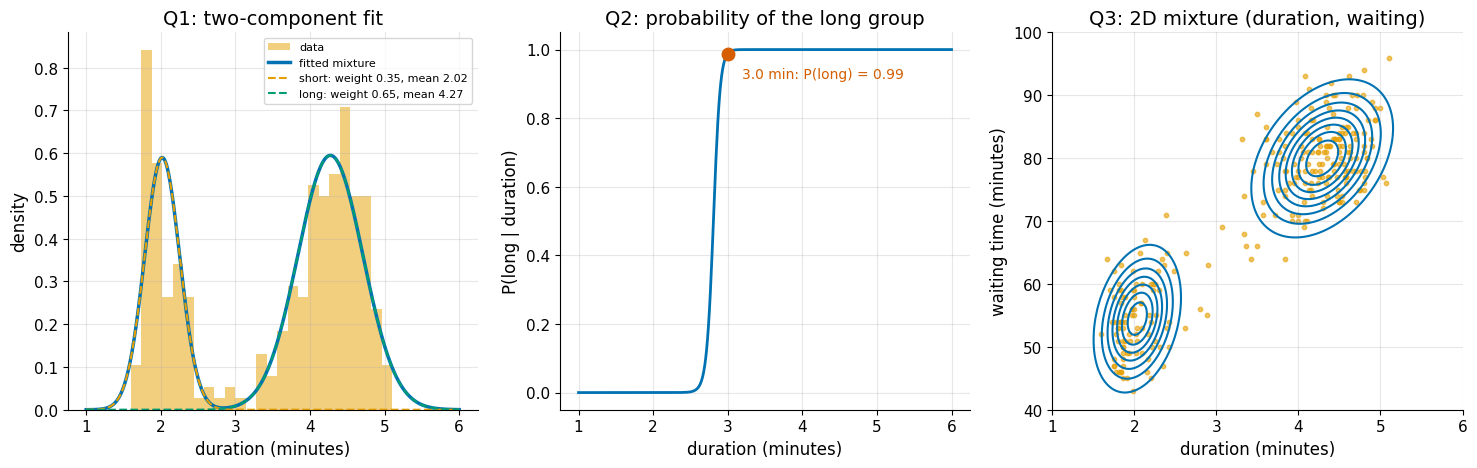

In [15]:
def em_2d(data, k, n_iterations, means_init):
    """Fit a k-component 2D Gaussian mixture with full covariances using EM."""
    n = len(data)
    pi = np.full(k, 1 / k)
    mu = np.array(means_init, dtype=float)
    cov = np.array([np.cov(data.T) for _ in range(k)])
    for _ in range(n_iterations):
        density = np.array([pi[j] * stats.multivariate_normal(mu[j], cov[j]).pdf(data) for j in range(k)])
        responsibilities = density / density.sum(axis=0)
        n_k = responsibilities.sum(axis=1)
        pi = n_k / n
        mu = (responsibilities @ data) / n_k[:, None]
        for j in range(k):
            diff = data - mu[j]
            cov[j] = (responsibilities[j][:, None] * diff).T @ diff / n_k[j] + 1e-6 * np.eye(2)
    log_likelihood = np.log(np.array([pi[j] * stats.multivariate_normal(mu[j], cov[j]).pdf(data) for j in range(k)]).sum(axis=0)).sum()
    return pi, mu, cov, log_likelihood

data_2d = np.column_stack([duration, waiting])
pi2, mu2, cov2, ll2 = em_2d(data_2d, 2, 150, means_init=[[2.0, 55.0], [4.3, 80.0]])
print("2D fit: weights", pi2.round(3), " means", mu2.round(2).tolist(), " log-likelihood", round(ll2, 2))
bic_2d = {}
for k in (1, 2, 3):
    inits = np.column_stack([np.linspace(duration.min() + 0.3, duration.max() - 0.3, k), np.linspace(waiting.min() + 5, waiting.max() - 5, k)])
    result = em_2d(data_2d, k, 150, inits)
    bic_2d[k] = (6 * k - 1) * np.log(len(data_2d)) - 2 * result[3]
print("2D BIC:", {k: round(v, 1) for k, v in bic_2d.items()})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))
d_axis = np.linspace(1, 6, 400)
axes[0].hist(duration, bins=25, density=True, color=SIM, alpha=0.5, label="data")
axes[0].plot(d_axis, fitted.pdf(d_axis), color=MAIN, linewidth=2.5, label="fitted mixture")
for w, c, name, color in zip(fitted.weights, fitted.components, ["short", "long"], COLORS[1:]):
    axes[0].plot(d_axis, w * c.pdf(d_axis), "--", color=color, label=f"{name}: weight {w:.2f}, mean {c.mean():.2f}")
axes[0].set_title("Q1: two-component fit")
axes[0].set_xlabel("duration (minutes)")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)

responsibility_curve = fitted.weights[1] * fitted.components[1].pdf(d_axis) / fitted.pdf(d_axis)
axes[1].plot(d_axis, responsibility_curve, color=MAIN, linewidth=2)
axes[1].plot([3.0], [p_long_code], "o", color=HIGHLIGHT, markersize=9)
axes[1].annotate(f"3.0 min: P(long) = {p_long_code:.2f}", (3.0, p_long_code), textcoords="offset points", xytext=(10, -18), color=HIGHLIGHT)
axes[1].set_title("Q2: probability of the long group")
axes[1].set_xlabel("duration (minutes)")
axes[1].set_ylabel("P(long | duration)")

g1, g2 = np.meshgrid(np.linspace(1, 6, 150), np.linspace(40, 100, 150))
dens2 = sum(w * stats.multivariate_normal(m, c).pdf(np.dstack([g1, g2])) for w, m, c in zip(pi2, mu2, cov2))
axes[2].scatter(duration, waiting, s=10, alpha=0.6, color=SIM)
axes[2].contour(g1, g2, dens2, levels=8, colors=MAIN)
axes[2].set_title("Q3: 2D mixture (duration, waiting)")
axes[2].set_xlabel("duration (minutes)")
axes[2].set_ylabel("waiting time (minutes)")
plt.show()

### 11.5 Interpretation and decision
- About **36 % of eruptions are short** (mean 2.0 minutes) and **64 % long** (mean 4.3 minutes); the within-group SDs are small (0.25 and 0.4 minutes), so the groups are very distinct.
- An eruption of **3.0 minutes** falls in the gap between the humps, yet the model assigns it to the long group with probability **0.99**: the short group is so tight (SD 0.24) that 3.0 is already 4 SDs above its mean. The 50/50 boundary is lower (about 2.8 minutes, see the responsibility curve).
- **BIC falls sharply from 1 to 2 components** (854 to 581) and hardly changes afterwards (581, 581, 577), so two components capture the structure; in the 2D fit BIC clearly prefers 2 (2322 versus 2334 for 3). A single Normal (mean 3.5, SD 1.1) would describe almost no actual eruption.
- **Decision for a visitor center:** predict the next waiting time using the group: after a short eruption expect about an hour (about 54 min), after a long one about 80 min. The 2D mixture captures this link between duration and waiting.

### 11.6 Extra example: customer spend segments
A shop's spend per visit is a mixture of **70 % casual customers** (mean 20, SD 5) and **30 % big spenders** (mean 60, SD 15). Questions: the overall mean and SD, the probability that a visit exceeds 50, and the spend above which a visit is more likely from a big spender.

In [16]:
w_c, w_b = 0.7, 0.3
mu_c, sd_c, mu_b, sd_b = 20.0, 5.0, 60.0, 15.0
mean_hand = w_c * mu_c + w_b * mu_b
variance_hand = w_c * sd_c**2 + w_b * sd_b**2 + w_c * (mu_c - mean_hand) ** 2 + w_b * (mu_b - mean_hand) ** 2     # within + between
p_over_50_hand = w_c * (1 - 0.5 * (1 + math.erf((50 - mu_c) / sd_c / math.sqrt(2)))) + w_b * (1 - 0.5 * (1 + math.erf((50 - mu_b) / sd_b / math.sqrt(2))))

customers = Mixture1D([w_c, w_b], [mu_c, mu_b], [sd_c, sd_b])
p_over_50_code = 1 - customers.cdf(50)
spend_grid = np.linspace(10, 60, 5001)
big_share = w_b * stats.norm(mu_b, sd_b).pdf(spend_grid) / customers.pdf(spend_grid)
boundary = spend_grid[np.argmax(big_share > 0.5)]
assert np.isclose(p_over_50_hand, p_over_50_code)
visits = customers.rvs(200_000, np.random.default_rng(3))
print(f"mean {mean_hand:.1f} (simulated {visits.mean():.2f}), SD {math.sqrt(variance_hand):.2f} (simulated {visits.std():.2f}); P(spend > 50) = {p_over_50_code:.4f} (simulated {np.mean(visits > 50):.4f}); big spenders more likely above {boundary:.1f}")
assert abs(visits.std() - math.sqrt(variance_hand)) < 0.2

mean 32.0 (simulated 32.05), SD 20.52 (simulated 20.55); P(spend > 50) = 0.2243 (simulated 0.2253); big spenders more likely above 33.3


**Interpretation.** The average visit is **32** but almost nobody spends 32: spending clusters around 20 and 60. **About 22 % of visits exceed 50** and a visit above about **33** is more likely to come from a big spender, which can drive targeted offers. Treating all customers as one Normal would hide the two segments.

---
### Example 2: response times from a cache and a database (mixture moments and responsibilities)

**Scenario (illustrative numbers).** **80 %** of requests are answered from a cache with latency Normal(**20** ms, SD **5**); **20 %** go to the database with latency Normal(**120** ms, SD **30**). The latency of a random request has a two-component Gaussian mixture distribution.

**Questions**
1. Find the mean and standard deviation of the latency.
2. A request took **60 ms**. What is the probability that it was a **database** request?
3. What are the **median** and the **99th percentile** of the latency (the SLA number)?

### 11.6 By hand

**Q1.** Mean $=0.8(20)+0.2(120)=\mathbf{40}$ ms. Within: $0.8(25)+0.2(900)=200$; between: $0.8(20-40)^2+0.2(120-40)^2=320+1280=1600$. Total variance $1800$, $\mathrm{SD}=\mathbf{42.4}$ ms.

**Q2.** Densities at 60 ms: cache $\phi\big(\frac{60-20}{5}\big)/5=\phi(8)/5\approx1.0\times10^{-16}$ (practically 0); database $\phi\big(\frac{60-120}{30}\big)/30=\phi(2)/30=0.00180$. With weights: $\dfrac{0.2\times0.00180}{0.8\times1.0\times10^{-16}+0.2\times0.00180}\approx\mathbf{1.000}$: a 60 ms request is certainly a database request.

**Q3.** The 50th and 99th percentiles solve $F(x)=0.5$ and $0.99$ for the mixture CDF $0.8\Phi(\frac{x-20}5)+0.2\Phi(\frac{x-120}{30})$; numerically about **21.6 ms** and **169.3 ms**.

mean 40.0, variance 1800, SD 42.43 | responsibilities at 60 ms: [0. 1.] | at 30 ms: [0.9966 0.0034] | median 21.6 ms, 95th 140.2, 99th 169.3 ms
simulation: mean 39.91, SD 42.34, median 21.6, 99th percentile 169.3, share of requests above 60 ms = 0.1946


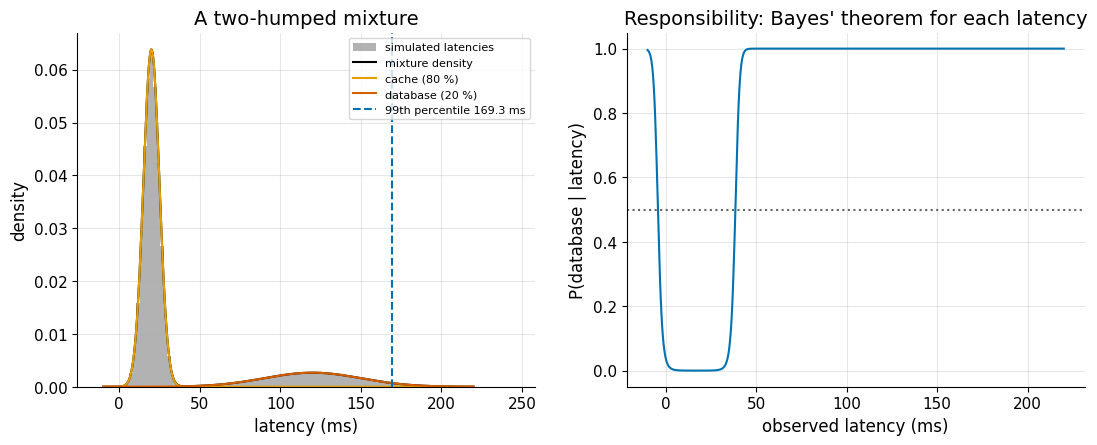

In [17]:
from scipy import optimize
w_a = np.array([0.8, 0.2]); m_a = np.array([20.0, 120.0]); s_a = np.array([5.0, 30.0])
mean_mix = (w_a * m_a).sum(); var_mix = (w_a * s_a ** 2).sum() + (w_a * (m_a - mean_mix) ** 2).sum()
cdf_mix = lambda x: (w_a * stats.norm.cdf(x, m_a, s_a)).sum(); pdf_mix = lambda x: (w_a * stats.norm.pdf(x, m_a, s_a)).sum()
q_a = lambda pr: optimize.brentq(lambda x: cdf_mix(x) - pr, -50, 400)
resp_60 = w_a * stats.norm.pdf(60, m_a, s_a) / pdf_mix(60); resp_30 = w_a * stats.norm.pdf(30, m_a, s_a) / pdf_mix(30)
print(f"mean {mean_mix:.1f}, variance {var_mix:.0f}, SD {np.sqrt(var_mix):.2f} | responsibilities at 60 ms: {resp_60.round(4)} | at 30 ms: {resp_30.round(4)} | median {q_a(0.5):.1f} ms, 95th {q_a(0.95):.1f}, 99th {q_a(0.99):.1f} ms")
assert np.isclose(mean_mix, 40) and np.isclose(var_mix, 1800) and resp_60[1] > 0.999 and abs(q_a(0.99) - 169.3) < 0.5
comp_a = np.random.default_rng(3).random(600_000) < 0.2; lat_a = np.where(comp_a, np.random.default_rng(4).normal(120, 30, 600_000), np.random.default_rng(5).normal(20, 5, 600_000))
print(f"simulation: mean {lat_a.mean():.2f}, SD {lat_a.std():.2f}, median {np.median(lat_a):.1f}, 99th percentile {np.percentile(lat_a, 99):.1f}, share of requests above 60 ms = {np.mean(lat_a > 60):.4f}")
assert abs(lat_a.std() - np.sqrt(var_mix)) < 0.2 and abs(np.percentile(lat_a, 99) - q_a(0.99)) < 1.5
xs_a = np.linspace(-10, 220, 600); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(lat_a, bins=120, density=True, color=NEUTRAL, alpha=0.5, label="simulated latencies"); axes[0].plot(xs_a, [pdf_mix(xq) for xq in xs_a], color="black", label="mixture density")
for k_, c_ in enumerate([SIM, HIGHLIGHT]): axes[0].plot(xs_a, w_a[k_] * stats.norm.pdf(xs_a, m_a[k_], s_a[k_]), color=c_, label=["cache (80 %)", "database (20 %)"][k_])
axes[0].axvline(q_a(0.99), color=MAIN, linestyle="--", label="99th percentile 169.3 ms"); axes[0].set_xlabel("latency (ms)"); axes[0].set_ylabel("density"); axes[0].set_title("A two-humped mixture"); axes[0].legend(fontsize=8)
rs_a = w_a[1] * stats.norm.pdf(xs_a, m_a[1], s_a[1]) / np.array([pdf_mix(xq) for xq in xs_a]); axes[1].plot(xs_a, rs_a, color=MAIN); axes[1].axhline(0.5, color=NEUTRAL, linestyle=":"); axes[1].set_xlabel("observed latency (ms)"); axes[1].set_ylabel("P(database | latency)"); axes[1].set_title("Responsibility: Bayes' theorem for each latency")
plt.show()

### 11.7 Interpretation and decision (Example 2)

- The mean latency is **40 ms**, yet almost no request takes 40 ms: requests take either about 20 ms (cache) or about 120 ms (database). The standard deviation (42 ms) is dominated by the **between-group** part (1,600 of the 1,800 variance), so a single Normal with mean 40 and SD 42 would badly misdescribe the data.
- Any request above about 45 ms is **certainly a database request** (responsibility near 1: at 60 ms it is 1.000); a request of 30 ms is still a cache request with probability 0.997; the ambiguous zone is narrow because the components are well separated.
- The SLA numbers come from the mixture CDF: **median 21.6 ms, 95th percentile 140 ms, 99th percentile 169 ms**. The slowest 5 % of requests are all database requests (the 95th percentile of the mixture is the database's own 75th percentile).
- **Decision.** Improving the cache hit rate from 80 % to 90 % would cut the mean latency from 40 to 30 ms and move the 99th percentile much more; monitor the two groups separately, not the average.

---
### Example 3: EM step by step on six data points

**Scenario (illustrative).** Six measurements are **1.0, 1.2, 0.8, 4.8, 5.0, 5.3**. We fit a two-component Gaussian mixture with a common SD of 1 and equal weights, starting from means **0 and 6**.

**Questions**
1. Compute the responsibilities and the updated means after the **first EM iteration**.
2. How do the means evolve over 5 iterations?
3. Does the log-likelihood increase every time?

### 11.8 By hand

**Q1.** The responsibility of component 1 for $x$ with equal weights and SD 1 is $\dfrac{\phi(x-0)}{\phi(x-0)+\phi(x-6)}=\dfrac1{1+e^{(x-0)^2/2\cdot(-1)+(x-6)^2/2}}=\dfrac1{1+e^{6x-18}}$: for $x=1.0$ it is $0.99999$, for $x=4.8$ it is $e^{-10.8}\approx2\times10^{-5}$ (tiny). The first update gives the means $\approx(1.0,\,5.03)$ (responsibility-weighted averages, which are essentially the group means).

**Q2.** With such well separated data EM converges almost immediately: means $(1.0,5.03)$ already after one step.

**Q3.** EM never decreases the likelihood; we verify numerically.

iteration 1: log-likelihood before the step -12.6775 | new means [1.     5.0333] | weights [0.5 0.5]
iteration 2: log-likelihood before the step -9.7736 | new means [1.0015 5.032 ] | weights [0.5 0.5]
iteration 3: log-likelihood before the step -9.7736 | new means [1.0015 5.032 ] | weights [0.5 0.5]
iteration 4: log-likelihood before the step -9.7736 | new means [1.0015 5.032 ] | weights [0.5 0.5]
iteration 5: log-likelihood before the step -9.7736 | new means [1.0015 5.032 ] | weights [0.5 0.5]
first-step responsibility of component 1: [9.9999e-01 9.9998e-01 1.0000e+00 2.0000e-05 1.0000e-05 0.0000e+00]
EM on 500 simulated points (true weights 0.6/0.4, means 1/5, SD 1): weights [0.586 0.414], means [0.9   4.876], SDs [0.979 1.064]


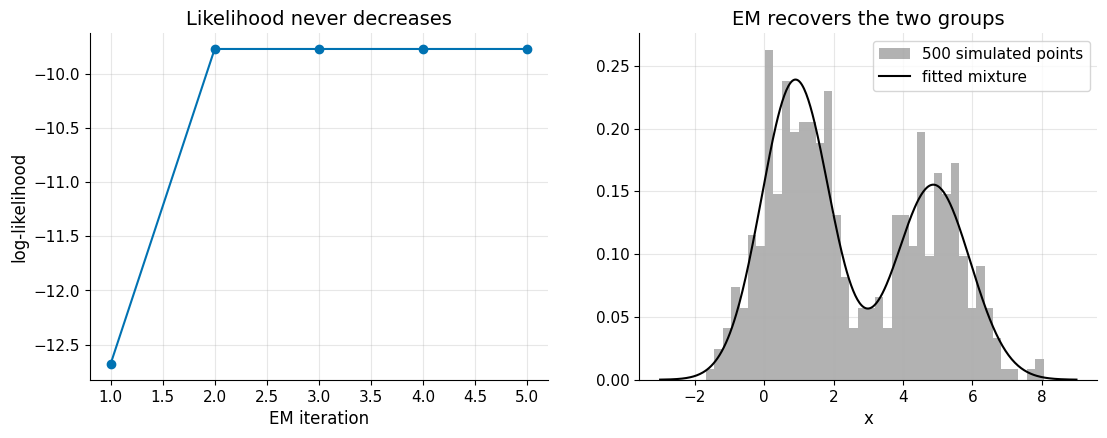

In [18]:
x_b = np.array([1.0, 1.2, 0.8, 4.8, 5.0, 5.3]); muem = np.array([0.0, 6.0]); w_b2 = np.array([0.5, 0.5]); sdem = 1.0
ll_hist = []
for it_b in range(1, 6):
    dens_b = w_b2 * stats.norm.pdf(x_b[:, None], muem, sdem)                          # n x 2 matrix of weighted component densities
    ll_hist.append(np.log(dens_b.sum(axis=1)).sum())
    resp_b = dens_b / dens_b.sum(axis=1, keepdims=True)                              # E-step: responsibilities
    muem = (resp_b * x_b[:, None]).sum(axis=0) / resp_b.sum(axis=0)                  # M-step: weighted means
    w_b2 = resp_b.mean(axis=0)
    print(f"iteration {it_b}: log-likelihood before the step {ll_hist[-1]:.4f} | new means {muem.round(4)} | weights {w_b2.round(3)}")
    if it_b == 1: first_resp = resp_b.copy()
print("first-step responsibility of component 1:", first_resp[:, 0].round(5))
assert all(np.diff(ll_hist) >= -1e-9) and abs(muem[0] - x_b[:3].mean()) < 5e-3 and abs(muem[1] - x_b[3:].mean()) < 5e-3
gm_b = np.random.default_rng(2); data_b = np.concatenate([gm_b.normal(1, 1, 300), gm_b.normal(5, 1, 200)]); mu_em2, w_em2, sd_em2 = np.array([0.0, 6.0]), np.array([0.5, 0.5]), np.array([1.0, 1.0])
for it_c in range(50):
    d_c = w_em2 * stats.norm.pdf(data_b[:, None], mu_em2, sd_em2); r_c = d_c / d_c.sum(axis=1, keepdims=True); nk_c = r_c.sum(axis=0)
    mu_em2 = (r_c * data_b[:, None]).sum(axis=0) / nk_c; sd_em2 = np.sqrt((r_c * (data_b[:, None] - mu_em2) ** 2).sum(axis=0) / nk_c); w_em2 = nk_c / data_b.size
print(f"EM on 500 simulated points (true weights 0.6/0.4, means 1/5, SD 1): weights {w_em2.round(3)}, means {mu_em2.round(3)}, SDs {sd_em2.round(3)}")
assert abs(w_em2[0] - 0.6) < 0.05 and abs(mu_em2[0] - 1) < 0.15 and abs(mu_em2[1] - 5) < 0.15
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, 6), ll_hist, "o-", color=MAIN); axes[0].set_xlabel("EM iteration"); axes[0].set_ylabel("log-likelihood"); axes[0].set_title("Likelihood never decreases")
xs_c = np.linspace(-3, 9, 400); axes[1].hist(data_b, bins=40, density=True, color=NEUTRAL, alpha=0.5, label="500 simulated points")
axes[1].plot(xs_c, (w_em2 * stats.norm.pdf(xs_c[:, None], mu_em2, sd_em2)).sum(axis=1), color="black", label="fitted mixture"); axes[1].set_xlabel("x"); axes[1].set_title("EM recovers the two groups"); axes[1].legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)

- With such separated data the **first iteration already assigns each point to the right group** (the responsibilities are 0.99999 or 0.00002) and the new means are the group averages, **1.0 and 5.03**; further iterations change almost nothing. The log-likelihood rises at the first step and then stays flat, as EM guarantees (it never decreases).
- The same algorithm applied to **500 noisy points** from a 60/40 mixture recovers weights near 0.6/0.4, means near 1 and 5 and SDs near 1 after a few dozen iterations.
- **Decision.** Use EM (or a library implementation) with **several different starting values** and keep the solution with the highest likelihood; choose the number of components with BIC or by checking that the fitted groups make sense, and be careful when the groups overlap, where the responsibilities stay uncertain.

## 12. Where it is used

### Statistics
- **Model-based clustering** and density estimation, finite-mixture models for heterogeneous populations, handling unobserved groups with the EM algorithm.

### Data science
- **Customer segmentation**, anomaly detection (low-density points), imputation, speaker and image segmentation; BIC to pick the number of segments.

### ML and AI
- **Gaussian mixture models (GMM)** as soft clustering, the EM algorithm as a template for latent-variable models (HMMs, topic models), mixture density networks, mixtures as flexible priors in VAEs.

## 13. Common pitfalls and misconceptions

- **EM finds a local maximum:** run several initializations and keep the best log-likelihood.
- **Label switching:** components have no inherent order; sort them (e.g. by mean) before comparing runs.
- **A component can collapse onto one point** (variance to 0, likelihood to infinity); add a small floor to the variance.
- **More components always fit better:** use BIC/AIC or hold-out likelihood, not the training likelihood.
- **Clusters need not be Gaussian:** a skewed group will be split into several components.
- **Responsibilities are model-based probabilities,** not certainties about the truth.

## 14. Exercises

1. A mixture is 30 % N(0, 1) and 70 % N(4, 2^2). Find its mean and variance.
2. For the mixture in exercise 1, find $P(\text{group 2}\mid x=2)$.
3. Show that adding a third component to a well-fitted 2-component model always cannot decrease the maximized log-likelihood, and explain why BIC may still prefer 2.
4. Compute BIC for the 2D geyser mixture with 2 versus 3 components from the notebook output and state the conclusion.
5. (Harder) Derive the M-step for the mixing weights by maximizing $\sum_i\sum_kr_{ik}\ln\pi_k$ subject to $\sum_k\pi_k=1$ (Lagrange multiplier).

6. Two components Normal(0,1) and Normal(4,1) have equal weights. Find the responsibility of the first component for $x=2$ and for $x=3$. Where is the boundary at which both are equally likely?
7. A mixture has weights (0.3, 0.7), means (10, 20) and SDs (2, 4). Compute its mean and variance, and check by simulation.
8. Explain in one sentence each why (a) a mixture density can have two humps even though each component is a bell curve, and (b) the EM algorithm's result depends on the starting point.

Solutions are at the end.

## 15. Summary table

| Item | Formula |
|---|---|
| Density | sum of pi_k N(x; mu_k, Sigma_k) |
| Mean | sum of pi_k mu_k |
| Variance (1D) | sum pi_k sigma_k^2 + sum pi_k (mu_k - mean)^2 |
| Responsibility | pi_k N_k(x) / sum_j pi_j N_j(x) |
| EM M-step | pi_k = N_k / n, mu_k = weighted mean, Sigma_k = weighted covariance |
| BIC | p ln n - 2 log-likelihood (lower is better) |
| Parameters | 1D: 3K - 1; 2D full: 6K - 1 |

## Solutions

In [19]:
w, m, s = np.array([0.3, 0.7]), np.array([0.0, 4.0]), np.array([1.0, 2.0])
mean1 = (w * m).sum()
var1 = (w * s**2).sum() + (w * (m - mean1) ** 2).sum()
print("1: mean =", mean1, " variance =", round(var1, 4))
p2 = 0.7 * stats.norm(4, 2).pdf(2) / (0.3 * stats.norm(0, 1).pdf(2) + 0.7 * stats.norm(4, 2).pdf(2))
print("2: P(group 2 | x = 2) =", round(p2, 4))
print("4: 2D BIC:", {k: round(v, 1) for k, v in bic_2d.items()})

1: mean = 2.8  variance = 6.46
2: P(group 2 | x = 2) = 0.8395
4: 2D BIC: {1: np.float64(2607.6), 2: np.float64(2322.2), 3: np.float64(2333.7)}


**1.** Mean $0.3\cdot0+0.7\cdot4=2.8$; variance $=0.3\cdot1+0.7\cdot4+0.3(0-2.8)^2+0.7(4-2.8)^2=0.3+2.8+2.352+1.008=6.46$.

**2.** $P=\dfrac{0.7\,\mathcal N(2\mid4,2)}{0.3\,\mathcal N(2\mid0,1)+0.7\,\mathcal N(2\mid4,2)}\approx0.84$ (printed).

**3.** A model with 2 components is a special case of one with 3 (set a weight to 0), so the maximized likelihood cannot decrease. BIC adds the penalty $p\ln n$ for the extra parameters, so it prefers 2 unless the likelihood gain is large.

**4.** The printed 2D BIC values (2607.6, 2322.2, 2333.7 for 1, 2, 3 components) are lowest for 2 components, the best trade-off.

**5.** Lagrangian $L=\sum_k N_k\ln\pi_k-\lambda(\sum\pi_k-1)$ with $N_k=\sum_ir_{ik}$; $\partial L/\partial\pi_k=N_k/\pi_k-\lambda=0\Rightarrow\pi_k=N_k/\lambda$; summing over $k$ gives $\lambda=n$, so $\pi_k=N_k/n$.

### Solutions to the additional exercises

Each answer is computed below and checked.

In [20]:
rs_f = lambda x_: stats.norm.pdf(x_, 0, 1) / (stats.norm.pdf(x_, 0, 1) + stats.norm.pdf(x_, 4, 1))
print(f"6: responsibility of component 1: x = 2 -> {rs_f(2.0):.3f}, x = 3 -> {rs_f(3.0):.4f}; boundary (equal weights and SDs) at the midpoint x = 2")
w7 = np.array([0.3, 0.7]); m7 = np.array([10.0, 20.0]); s7 = np.array([2.0, 4.0])
mean7 = (w7 * m7).sum(); var7 = (w7 * s7 ** 2).sum() + (w7 * (m7 - mean7) ** 2).sum()
sm7 = np.where(np.random.default_rng(5).random(500_000) < 0.3, np.random.default_rng(6).normal(10, 2, 500_000), np.random.default_rng(7).normal(20, 4, 500_000))
print(f"7: mean {mean7:.1f}, variance {var7:.2f} (within {(w7 * s7 ** 2).sum():.2f} + between {(w7 * (m7 - mean7) ** 2).sum():.2f}) | simulated mean {sm7.mean():.2f}, variance {sm7.var():.2f}")
print("8: (a) the density is a weighted sum of bells, and a sum of two bells with separated centres has a dip between them; (b) the likelihood has several local peaks and EM climbs to the nearest one")
assert np.isclose(rs_f(2.0), 0.5) and np.isclose(var7, 33.4) and abs(sm7.var() - var7) < 0.3

6: responsibility of component 1: x = 2 -> 0.500, x = 3 -> 0.0180; boundary (equal weights and SDs) at the midpoint x = 2
7: mean 17.0, variance 33.40 (within 12.40 + between 21.00) | simulated mean 17.01, variance 33.41
8: (a) the density is a weighted sum of bells, and a sum of two bells with separated centres has a dip between them; (b) the likelihood has several local peaks and EM climbs to the nearest one
